# Milestone 1: Skin Cancer Dataset Exploration (HAM10000)
**System**: Skin Cancer Detection and Classification System Using CNN-SVM  
**Objective**: Explore dataset labels, class distribution, lesion characteristics, and patient demographics.

In [1]:
import os, sys
project_root = os.path.abspath('..') if os.path.exists('../dataset') else os.path.abspath('.')
if project_root not in sys.path:
    sys.path.insert(0, project_root)
os.chdir(project_root)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from src.preprocessing import CLASS_NAMES, index_image_paths

sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.size': 11, 'figure.autolayout': True})
print('Environment and libraries initialized successfully.')

Environment and libraries initialized successfully.


## 1. Load Metadata and Index Images

In [2]:
metadata_path = os.path.join('dataset', 'raw', 'HAM10000_metadata.csv')
df = pd.read_csv(metadata_path)
print(f'Total records: {len(df)}')
print(f'Unique patient lesions: {df["lesion_id"].nunique()}')
image_map = index_image_paths()
print(f'Total images indexed: {len(image_map)}')
df.head()

2026-10-28 17:31:36,174 - INFO - Indexed 10015 images across search directories.


Total records: 10015
Unique patient lesions: 7470
Total images indexed: 10015


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


## 2. Diagnostic Categories & Class Imbalance Analysis
The 7 diagnostic classes in HAM10000 are:
- `nv`: Melanocytic Nevi (benign mole)
- `mel`: Melanoma (malignant)
- `bkl`: Benign Keratosis (benign)
- `bcc`: Basal Cell Carcinoma (malignant)
- `akiec`: Actinic Keratoses (pre-malignant / malignant)
- `vasc`: Vascular Lesions (benign)
- `df`: Dermatofibroma (benign)

,Code,Diagnosis,Count,Proportion (%)
0,nv,Melanocytic Nevi,6705,66.95
1,mel,Melanoma,1113,11.11
2,bkl,Benign Keratosis,1099,10.97
3,bcc,Basal Cell Carcinoma,514,5.13
4,akiec,Actinic Keratoses,327,3.27
5,vasc,Vascular Lesions,142,1.42
6,df,Dermatofibroma,115,1.15


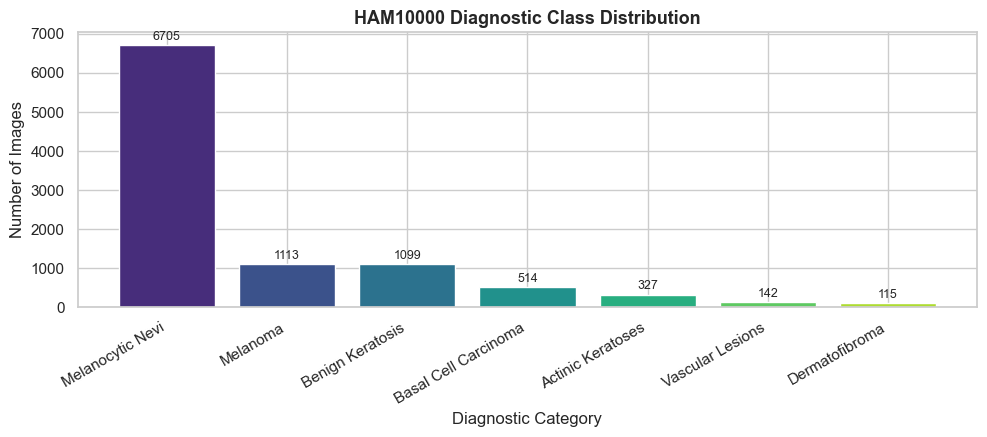

In [3]:
class_counts = df['dx'].value_counts()
class_df = pd.DataFrame({
    'Code': class_counts.index,
    'Diagnosis': [CLASS_NAMES[c] for c in class_counts.index],
    'Count': class_counts.values,
    'Proportion (%)': (class_counts.values / len(df) * 100).round(2)
})
display(class_df)

plt.figure(figsize=(10, 4.5))
bars = plt.bar(class_df['Diagnosis'], class_df['Count'], color=sns.color_palette('viridis', len(class_df)))
plt.title('HAM10000 Diagnostic Class Distribution', fontsize=13, fontweight='bold')
plt.xlabel('Diagnostic Category')
plt.ylabel('Number of Images')
plt.xticks(rotation=30, ha='right')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 60, f'{yval}', ha='center', va='bottom', fontsize=9)
plt.show()

## 3. Patient Demographics & Anatomical Distribution

C:\Users\USER\AppData\Local\Temp\ipykernel_19940\3409789853.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=loc_counts.values, y=loc_counts.index, palette='mako', ax=axes[1])


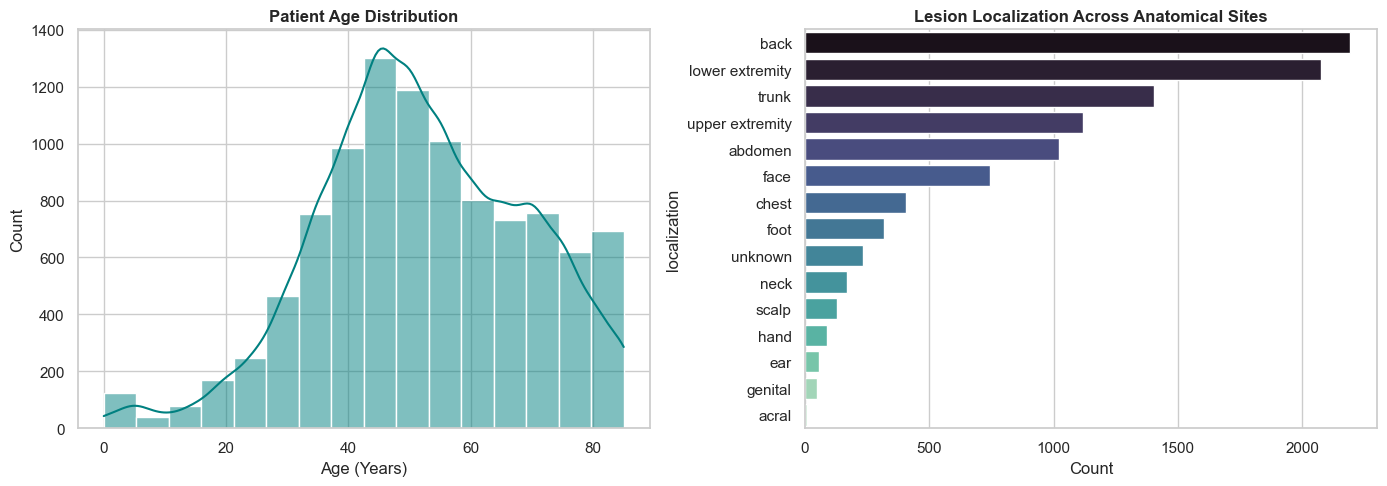

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

valid_age = df.dropna(subset=['age'])
sns.histplot(data=valid_age, x='age', kde=True, bins=16, color='teal', ax=axes[0])
axes[0].set_title('Patient Age Distribution', fontweight='bold')
axes[0].set_xlabel('Age (Years)')

loc_counts = df['localization'].value_counts()
sns.barplot(x=loc_counts.values, y=loc_counts.index, palette='mako', ax=axes[1])
axes[1].set_title('Lesion Localization Across Anatomical Sites', fontweight='bold')
axes[1].set_xlabel('Count')

plt.tight_layout()
plt.show()

## 4. Sample Lesions from Each Diagnostic Category

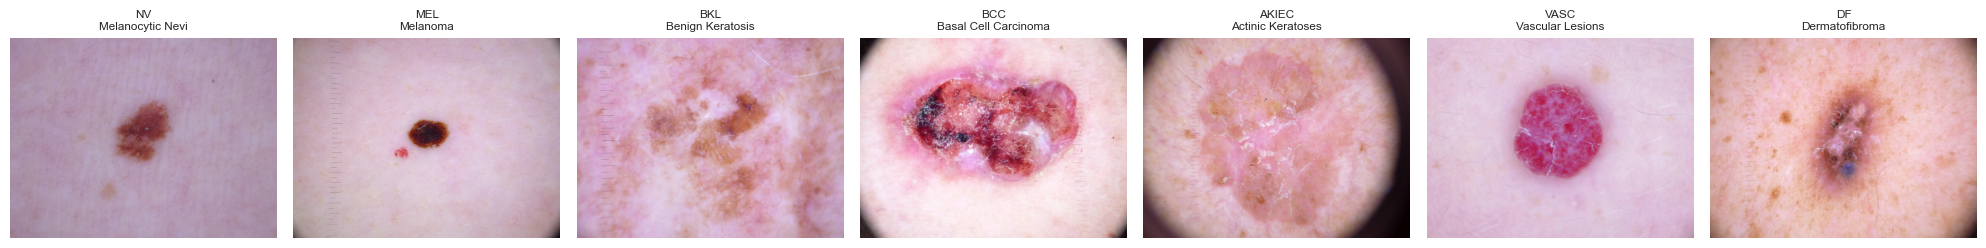

In [5]:
fig, axes = plt.subplots(1, 7, figsize=(20, 3))
for idx, (code, name) in enumerate(CLASS_NAMES.items()):
    sample_img_id = df[df['dx'] == code].iloc[0]['image_id']
    img_path = image_map[sample_img_id]
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    axes[idx].imshow(img)
    axes[idx].set_title(f"{code.upper()}\n{name}", fontsize=8.5)
    axes[idx].axis('off')
plt.tight_layout()
plt.show()